In [64]:
import control as ctrl
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [71]:
# Transfer Functions

# 6/(s+1)(s+2)(s+3)
G1 = ctrl.TransferFunction([6], [1, 6, 11, 6])

# 2(s+2)/s^3 - 3s^2 + 2s + 4
G2 = ctrl.TransferFunction([2, 4], [1, -3, 2, 4])

# 1/s^4 + 5s^3 + 2s^2 - 7s + 1
G3 = ctrl.TransferFunction([1], [1, 5, 2, -7, 1])

# 12(s+2)/(s-1)(s-2)(s+3)(s+4)
G4 = ctrl.TransferFunction([12, 24], [1, 4, -7, -22, 24])

# 120/(s+1)(s+2)(s+3)(s+4)(s+5)
G5 = ctrl.TransferFunction(
    [120],
    [1, 15, 85, 225, 274, 120]
)

# 720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)
G6 = ctrl.TransferFunction(
    [720],
    [1, 21, 175, 735, 1624, 1764, 720]
)

# Fix Kd
Kd = 0.5
systems = {
    "-6/(s+1)(s-2)(s+3)": G1,
    "2(s+2)/s^3 - 3s^2 + 2s + 4": G2,
    "1/s^4 + 5s^3 + 2s^2 - 7s + 1": G3,
    "12(s+2)/(s-1)(s-2)(s+3)(s+4)": G4,
    "120/(s+1)(s+2)(s+3)(s+4)(s+5)": G5,
    "720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)": G6
}

output_dir = Path(r"C:\Users\admin\Desktop\PID_Project\pid_stability_boundaries")
output_dir.mkdir(parents = True, exist_ok=True)

In [66]:
# Check stability

def get_closed_loop_poles(Kp, Ki, Kd, plant):
    # PID controller: Kd*s^2 + Kp*s + Ki, divided by s
    controller = ctrl.TransferFunction(
        [Kd, Kp, Ki], [1, 0]
    )

    closed_loop = ctrl.feedback(controller * plant, 1)
    return np.asarray(ctrl.poles(closed_loop))


def is_stable(Kp, Ki, Kd, plant, eps=1e-8):
    poles = get_closed_loop_poles(Kp, Ki, Kd, plant)

    # Strict continuous-time stability
    return bool(np.all(np.real(poles) < -eps))

In [ ]:
def trace_ray(
    theta,
    plant,
    Kd,
    max_t=100,
    scan_steps=300,
    binary_iterations=40
):
    """
    Return all detected stability transitions on one ray.

    theta: ray angle in radians
    t: distance from origin
    """

    def gains(t):
        return t * np.cos(theta), t * np.sin(theta)

    t_values = np.linspace(0.0, max_t, scan_steps + 1)

    # Stability at every sampled point
    stable_values = []

    for t in t_values:
        Kp, Ki = gains(t)
        stable_values.append(is_stable(Kp, Ki, Kd, plant))

    transitions = []

    for i in range(len(t_values) - 1):
        if stable_values[i] == stable_values[i + 1]:
            continue

        # A transition lies between t_values[i] and t_values[i+1]
        low = t_values[i]
        high = t_values[i + 1]
        left_is_stable = stable_values[i]

        # Refine this individual transition
        for _ in range(binary_iterations):
            mid = (low + high) / 2
            Kp_mid, Ki_mid = gains(mid)
            mid_is_stable = is_stable(Kp_mid, Ki_mid, Kd, plant)

            if mid_is_stable == left_is_stable:
                low = mid
            else:
                high = mid

        t_boundary = (low + high) / 2
        Kp_boundary, Ki_boundary = gains(t_boundary)

        transitions.append({
            "t": t_boundary,
            "Kp": Kp_boundary,
            "Ki": Ki_boundary,
            "transition": (
                "Stable -> Unstable"
                if left_is_stable
                else "Unstable -> Stable"
            )
        })

    return transitions

Processing -6/(s+1)(s-2)(s+3)...


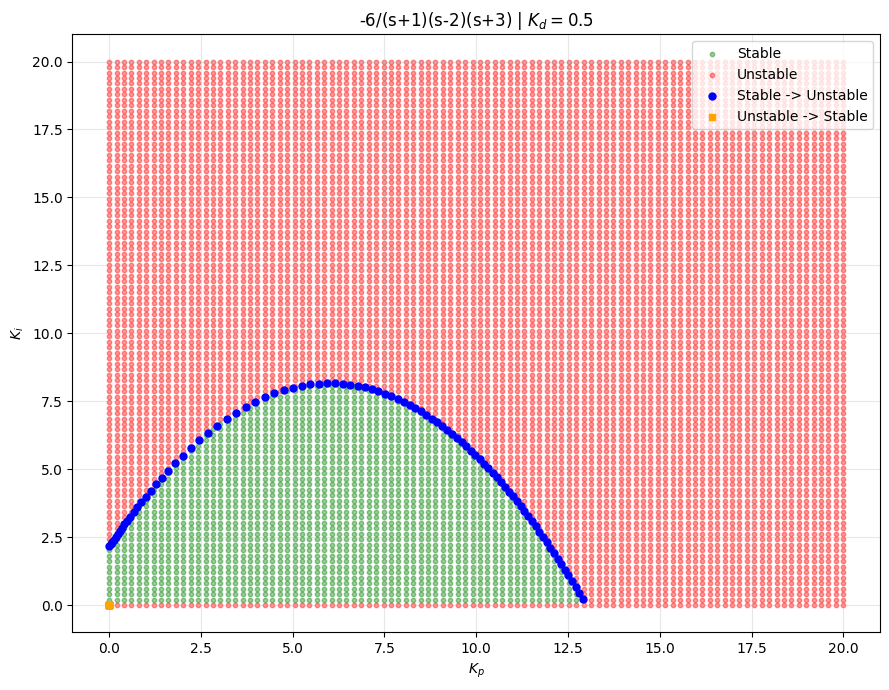

Boundary transitions detected: 180
Processing 2(s+2)/s^3 - 3s^2 + 2s + 4...


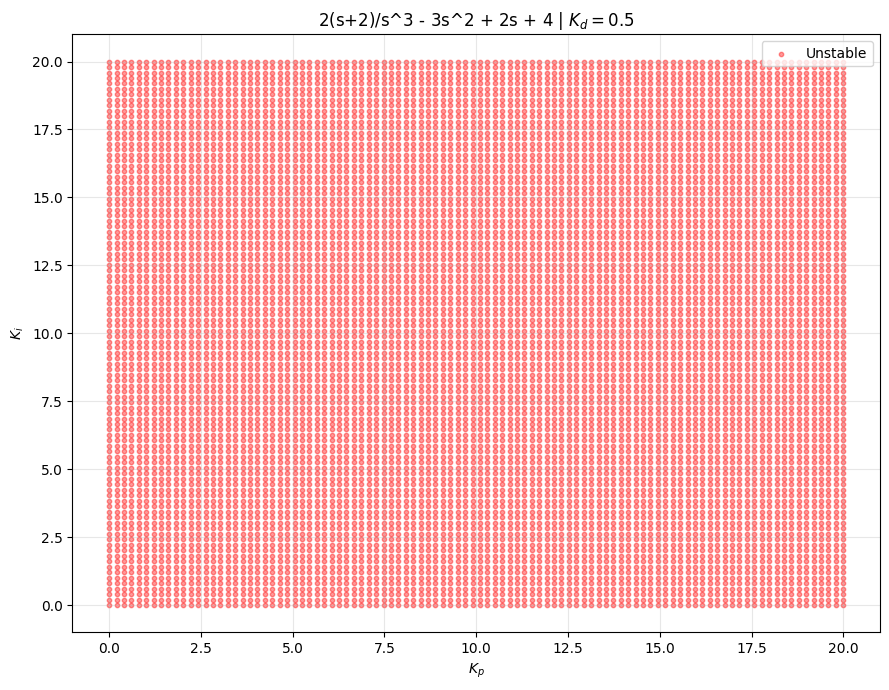

Boundary transitions detected: 0
Processing 1/s^4 + 5s^3 + 2s^2 - 7s + 1...


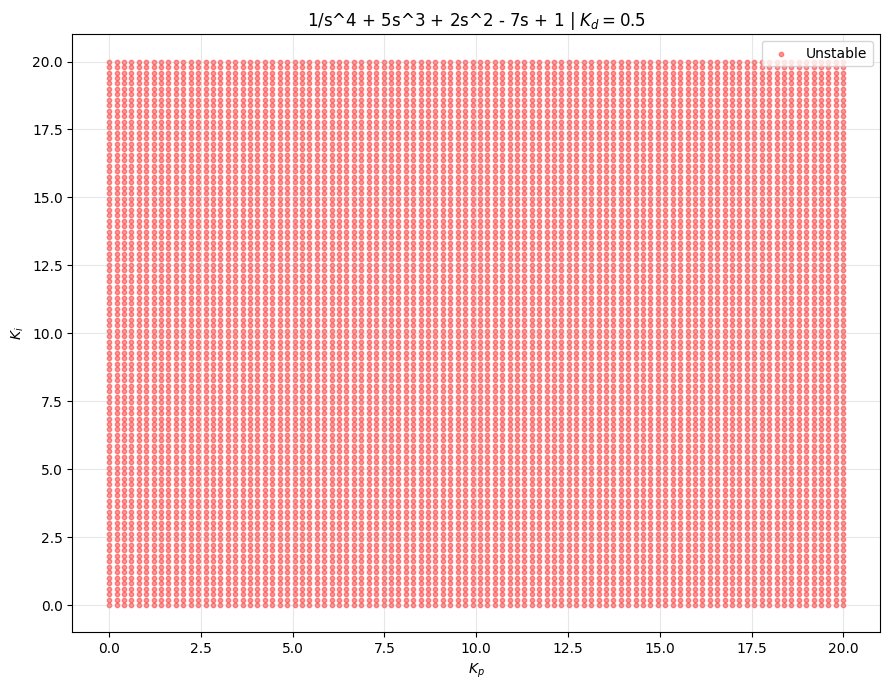

Boundary transitions detected: 0
Processing 12(s+2)/(s-1)(s-2)(s+3)(s+4)...


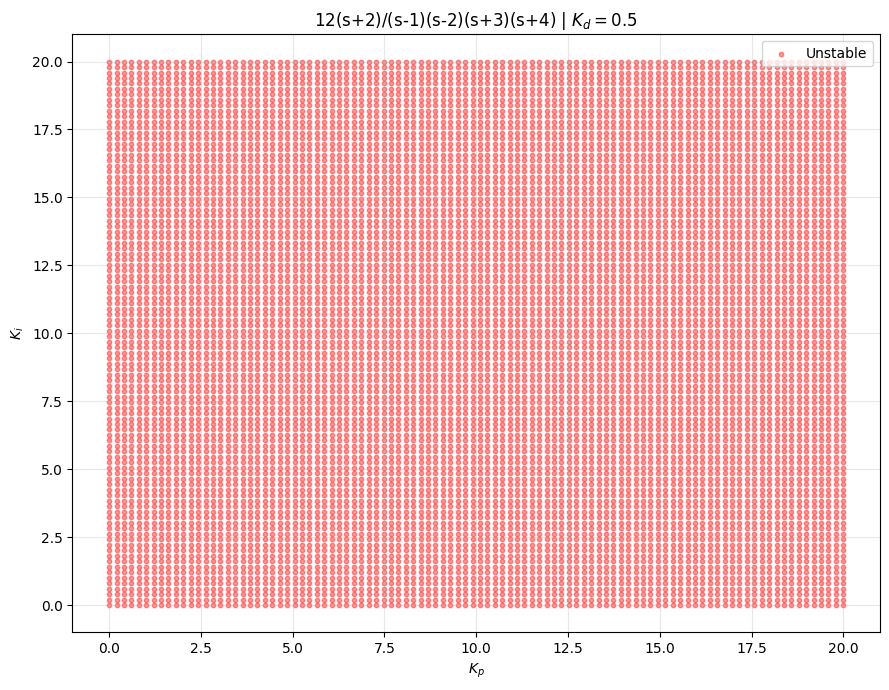

Boundary transitions detected: 0
Processing 120/(s+1)(s+2)(s+3)(s+4)(s+5)...


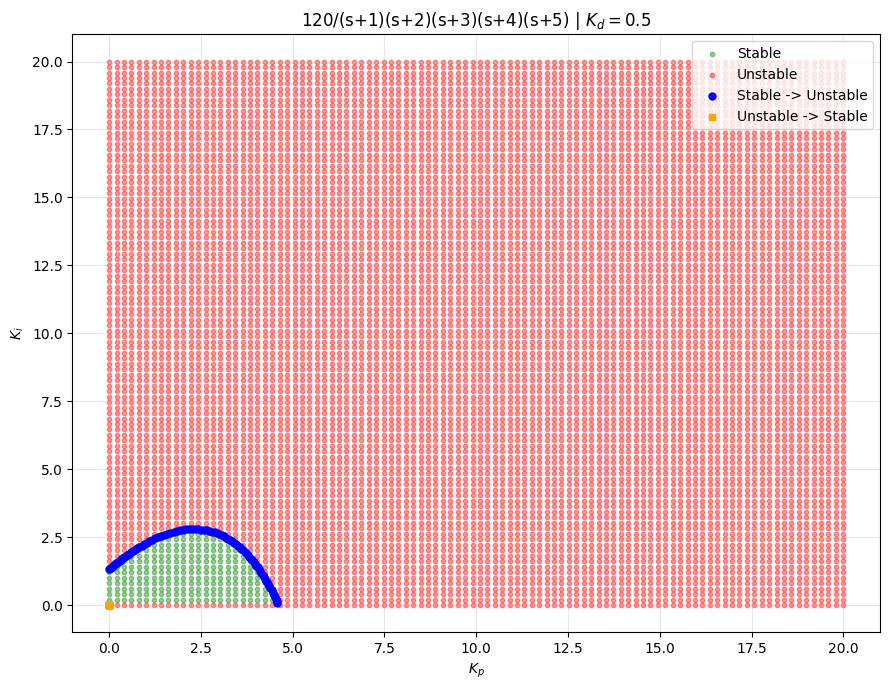

Boundary transitions detected: 180
Processing 720/(s+1)(s+2)(s+3)(s+4)(s+5)(s+6)...


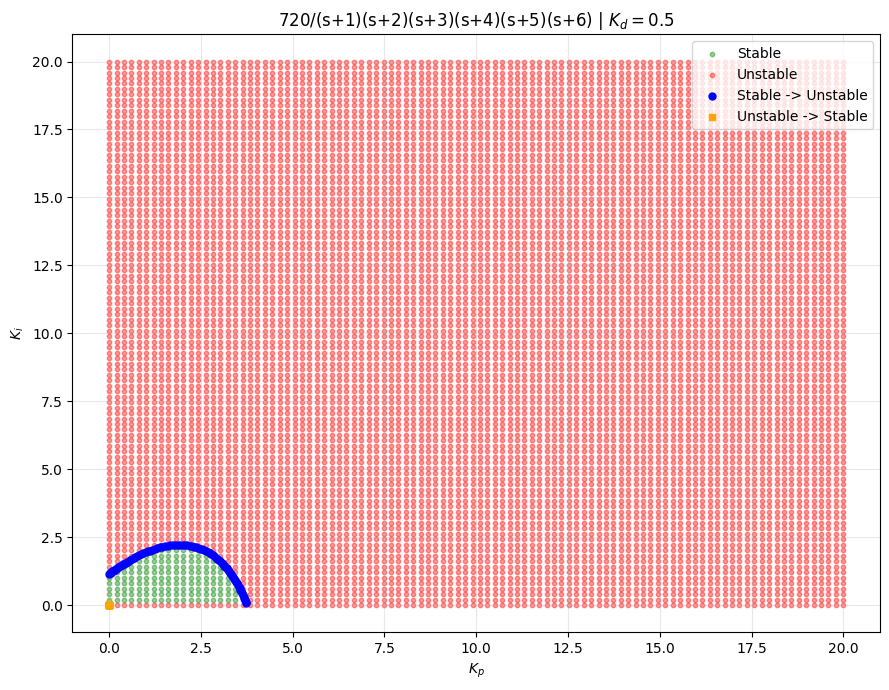

Boundary transitions detected: 180


In [73]:
# Stability map settings
Kp_grid = np.linspace(0, 20, 100)
Ki_grid = np.linspace(0, 20, 100)

angles_deg = np.linspace(0, 90, 91)

for system_name, plant in systems.items():
    print(f"Processing {system_name}...")

    # Trace boundaries for this exact system key
    records = []

    for angle_deg in angles_deg:
        transitions = trace_ray(
            theta=np.deg2rad(angle_deg),
            plant=plant,
            Kd=Kd,
            max_t=14.2,
            scan_steps=300,
            binary_iterations=40
        )

        for point in transitions:
            records.append({
                "angle_degrees": angle_deg,
                "Kp": point["Kp"],
                "Ki": point["Ki"],
                "transition": point["transition"]
            })

    df = pd.DataFrame(records)

    # Calculate stable and unstable grid points
    stable_pts = []
    unstable_pts = []

    for Kp in Kp_grid:
        for Ki in Ki_grid:
            if is_stable(Kp, Ki, Kd, plant):
                stable_pts.append((Kp, Ki))
            else:
                unstable_pts.append((Kp, Ki))

    stable_pts = np.asarray(stable_pts).reshape(-1, 2)
    unstable_pts = np.asarray(unstable_pts).reshape(-1, 2)

    # Plot
    plt.figure(figsize=(9, 7))

    if len(stable_pts):
        plt.scatter(
            stable_pts[:, 0], stable_pts[:, 1],
            color="green", s=10, alpha=0.4,
            label="Stable"
        )

    if len(unstable_pts):
        plt.scatter(
            unstable_pts[:, 0], unstable_pts[:, 1],
            color="red", s=10, alpha=0.4,
            label="Unstable"
        )

    if not df.empty:
        for transition, color, marker in [
            ("Stable -> Unstable", "blue", "o"),
            ("Unstable -> Stable", "orange", "s")
        ]:
            subset = df[df["transition"] == transition]

            if not subset.empty:
                plt.scatter(
                    subset["Kp"], subset["Ki"],
                    color=color, marker=marker, s=25,
                    label=transition, zorder=5
                )

    plt.xlabel("$K_p$")
    plt.ylabel("$K_i$")
    plt.title(f"{system_name} | $K_d={Kd}$")

    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"Boundary transitions detected: {len(df)}")